# 04 — Delta-hedged option selling (synthetic chains)

**Read the caveat first.** No historical SPY chains are freely available, so
options here are Black-Scholes-priced from real SPY closes with the real VIX as
ATM IV and a *fixed* parametric skew (`data/options.py`). Real mechanics
(daily hedging, exits, costs, decomposition) on model prices: treat levels as a
sketch, not a track record. With IV set to VIX and BS pricing, a positive
theta−gamma spread is partly baked in whenever VIX > subsequent RV — which is
the very premium measured in notebook 01, but with none of the smile dynamics,
vol-of-vol marks, or gap microstructure a real book would carry.

Re-derive with `python -m scripts.run_delta_hedged`.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import logging
logging.disable(logging.WARNING)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from vrp_lab.config import load_config, PROCESSED, REPORTS
cfg = load_config()
%config InlineBackend.figure_format = "retina"


In [2]:
results = pd.read_csv(REPORTS / "delta_hedged_results.csv", index_col=0)
hist = pd.read_csv(PROCESSED / "delta_hedged_history.csv", index_col=0, parse_dates=True)
results.round(3)

,straddle,straddle_tail_hedged,strangle_10d,strangle_10d_tail_hedged
ann_return,0.045,0.038,0.030,0.022
ann_vol,0.010,0.018,0.005,0.017
sharpe,1.393,0.437,0.135,-0.420
sortino,1.721,0.605,0.151,-0.594
calmar,2.837,0.897,3.251,0.430
max_drawdown,-0.016,-0.042,-0.009,-0.052
dd_duration_days,16.000,122.000,5.000,318.000
dd_recovery_days,69.000,344.000,193.000,806.000
cvar_95,-0.002,-0.003,-0.001,-0.002
cvar_99,-0.004,-0.006,-0.002,-0.006


## P&L decomposition — the measurement that matters
$\Delta V \approx \Delta\,dS + \tfrac12\Gamma\,dS^2 + \nu\,d\sigma + \Theta\,dt$ — for a delta-hedged short book, **theta collected vs gamma paid is the realized VRP**. Residual = higher-order greeks + discrete hedging.

In [3]:
from vrp_lab.risk.pnl_decomp import decompose, attribution_summary
d = decompose(hist[hist["in_position"]])
attribution_summary(d).round(0)

theta_pnl           1609495.0
gamma_pnl          -1066207.0
vega_pnl             -48509.0
delta_pnl            -30692.0
residual              86651.0
option_pnl           550737.0
theta_plus_gamma     543288.0
Name: cumulative_pnl, dtype: float64

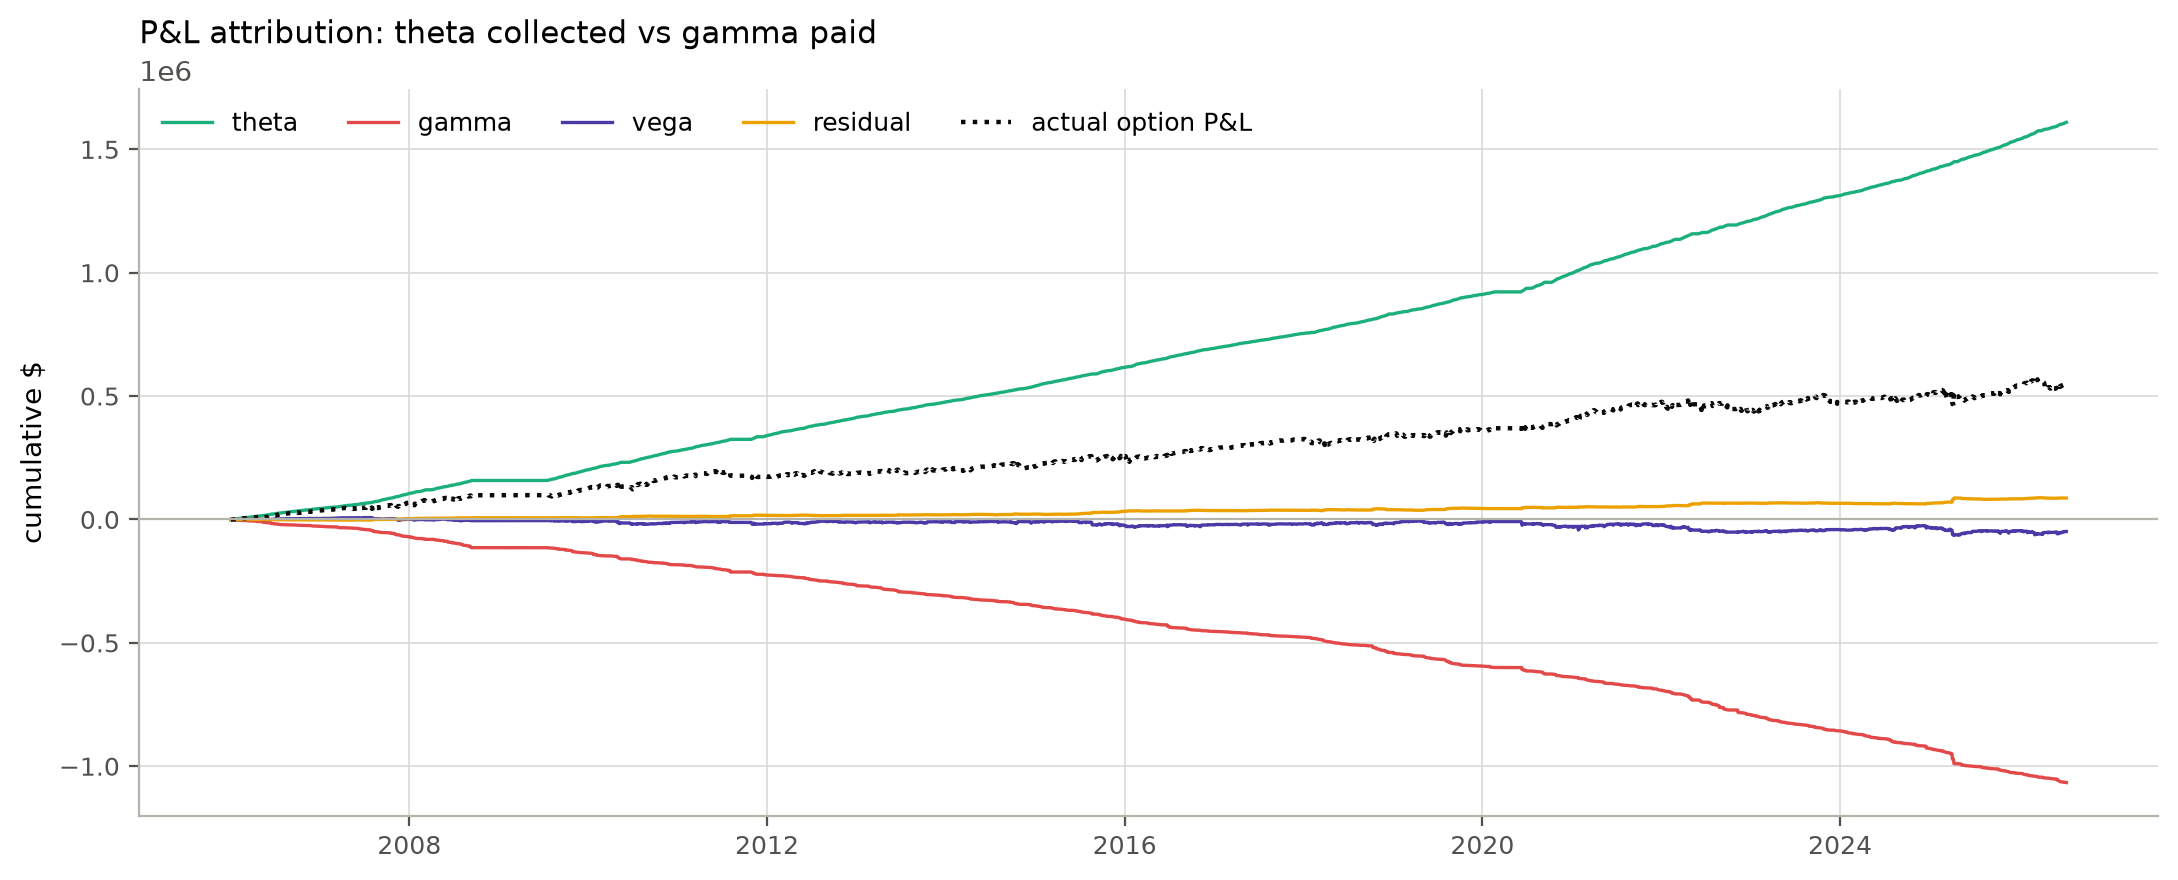

In [4]:
from vrp_lab.visualization.plots import plot_pnl_attribution, plot_gamma_vs_move
plot_pnl_attribution(d);

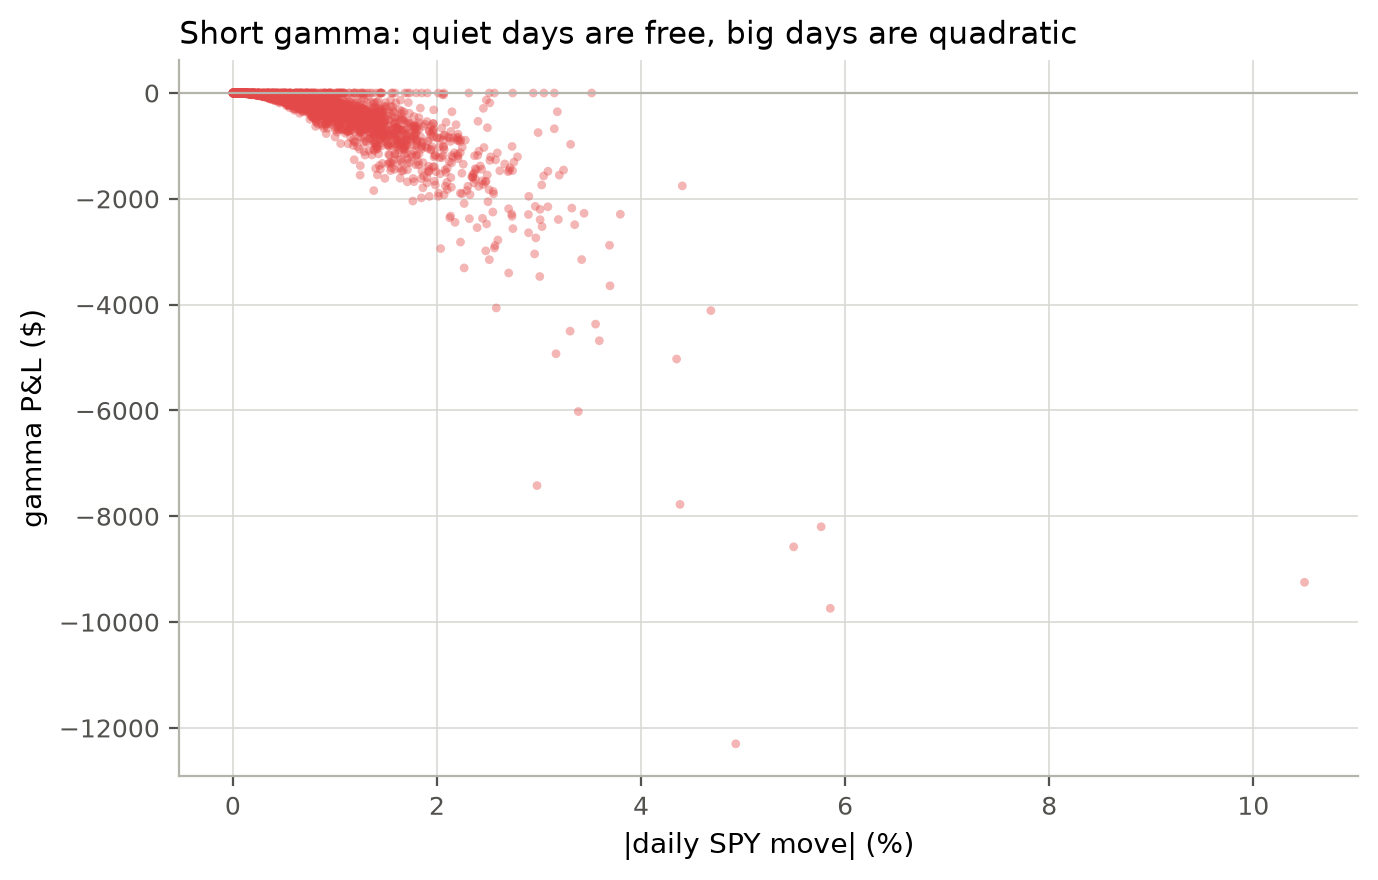

In [5]:
from vrp_lab.data.yfinance import pull_ohlcv
spy = pull_ohlcv("SPY", cfg["date_range"]["start"])["close"]
plot_gamma_vs_move(d, spy);

Gamma P&L against |move| is negative and quadratic — the visual definition of short gamma. The hedge neutralizes *direction* (delta P&L ≈ 0 above), never *convexity*.

## The tail hedge trade-off
The 5Δ/2Δ put spread costs Sharpe (1.39 → 0.44 here) and buys skew (−3.3 → −0.1) and a bounded left tail. In BS-world the hedge looks maximally unattractive — flat smile means crash wings are priced *without* crash premium, yet it still only halves the Sharpe. On a real smile you pay more; the point of showing it is the shape of the trade-off, not the exact number.

In [6]:
cols = ["sharpe", "max_drawdown", "cvar_99", "skew", "worst_day"]
results.loc[cols].T.round(3)

,sharpe,max_drawdown,cvar_99,skew,worst_day
straddle,1.393,-0.016,-0.004,-3.329,-0.009
straddle_tail_hedged,0.437,-0.042,-0.006,-0.080,-0.015
strangle_10d,0.135,-0.009,-0.002,-7.282,-0.006
strangle_10d_tail_hedged,-0.420,-0.052,-0.006,0.603,-0.014
